
**Завдання 1**: Завантажте дані `medical-charges.csv` в пандас датафрейм і виведіть перші 5 записів. Напишіть, як ви можете підійти до вирішення задачі прогнозування колонки `charges` на основі інших колонок виходячи з наявних на даний момент знань (без ML методів, чисто з використанням аналітики). Запишіть 3 або більше ідей, які приходять вам на думку нижче:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option('display.max.rows',130)
pd.set_option('display.max.columns',130)
pd.set_option('float_format', '{:.2f}'.format)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
df = pd.read_csv("*medical-charges.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.92
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86


1. Вплив куріння на вартість страхування. Очікується, що курці матимуть значно вищі витрати на медичне страхування через підвищені ризики для здоров'я.
2. Залежність вартості страхування від віку. Розрахувати середнє значення charges для кожної групи по віку. Це дозволить визначити, як вік впливає на вартість страхування.
3. Вплив індексу маси тіла (BMI).Особливу увагу приділити людям із високим BMI, оскільки надмірна вага може бути пов'язана з додатковими ризиками для здоров'я.
4. Вплив кількості дітей на вартість страхування.
5. Комплексний аналіз декількох характеристик. Дослідити комбінацію декількох факторів, наприклад, віку, BMI та статусу курця.

**Завдання 2**: Візуалізуйте розподіл медичних зборів (`charges`) у вигляді інтерактивної гістограми plotly з розбиттями за категоріями ознак
1. `sex`
2. `region`

Додайте маржинальний графік у вигляді бокс-плота вгорі по дикретним категоріям ознак.
Скористайтесь прикладом візуалізації з лекції.
Опишіть свої спостереження.

In [3]:
fig = px.histogram(
    df,
    x='charges',
    color='sex',
    marginal='box',
    nbins=40,
    barmode='overlay',
    opacity=0.6,
    histnorm='probability density',
    title='Розподіл медичних витрат залежно від статі'
)

fig.update_layout(
    xaxis_title='Медичні витрати (charges)',
    yaxis_title='Щільність розподілу',
    legend_title='Стать'
)

fig.show()

In [4]:
fig = px.histogram(
    df,
    x='charges',
    color='region',
    marginal='box',
    nbins=40,
    barmode='overlay',
    opacity=0.6,
    histnorm='probability density',
    title='Розподіл медичних витрат залежно від регіону'
)

fig.update_layout(
    xaxis_title='Медичні витрати (charges)',
    yaxis_title='Щільність розподілу',
    legend_title='Регіон'
)

fig.show()

In [5]:
display(
    df.groupby('sex')['charges']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

display(
    df.groupby('region')['charges']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

,count,mean,median,std
sex,,,,
female,662,12569.58,9412.96,11128.70
male,676,13956.75,9369.62,12971.03


,count,mean,median,std
region,,,,
northeast,324,13406.38,10057.65,11255.80
northwest,325,12417.58,8965.80,11072.28
southeast,364,14735.41,9294.13,13971.10
southwest,325,12346.94,8798.59,11557.18


За ознакою sex:
- Розподіли медичних витрат чоловіків і жінок мають подібну форму та значною мірою перекриваються.
- В обох групах спостерігається правостороння асиметрія: більшість медичних витрат зосереджена в діапазоні приблизно до 15000, проте є значна кількість великих значень.
- Середні витрати чоловіків вищі (13956.75), ніж жінок (12569.58).
- Водночас медіанні значення майже однакові: 9369.62 у чоловіків та 9412.96 у жінок.
- Стандартне відхилення у чоловіків також вище, що свідчить про більший розкид значень медичних витрат.
Висновок: стать не демонструє суттєвої різниці в типовому рівні медичних витрат, оскільки медіани майже однакові. Проте чоловіки мають дещо вищі середні витрати та більшу варіативність показника.


За ознакою region:
- У всіх чотирьох регіонах розподіл медичних витрат має правосторонню асиметрію.
- Основна частина витрат зосереджена в нижньому діапазоні, проте в кожному регіоні присутні клієнти з дуже високими витратами.
- Найвище середнє значення витрат спостерігається у регіоні Southeast - 14735.41.
- Найвище медіанне значення спостерігається у регіоні Northeast - 10057.65.
- Найменше середнє значення витрат має регіон Southwest - 12346.94, а найменша медіана також у Southwest - 8798.59.
- Найбільший розкид витрат спостерігається у Southeast (стандартне відхилення 13971.10).
- Розподіли регіонів значною мірою перекриваються, тому відмінності між ними не є однозначними.
Висновок: регіон може бути пов'язаний із певними відмінностями у медичних витратах. Зокрема, Southeast характеризується найвищими середніми витратами та найбільшою варіативністю. Водночас у Northeast спостерігається найвище медіанне значення.

Загалом, розподіл медичних витрат залежить від статі та регіону: в обох випадках розподіли мають правосторонню асиметрію та містять значну кількість великих значень. За ознакою статі суттєвої різниці між медіанними витратами чоловіків і жінок не виявлено, хоча середні витрати чоловіків дещо вищі. За ознакою регіону спостерігаються певні відмінності: найвищі середні витрати зафіксовані у southeast, а найвище медіанне значення — у northeast.

**Завдання 3**: Візуалізуйте з `plotly` розподіл кожного з настуних стовпців відносно того, чи є людина курцем (`smoker`)
- `region`
- `children`

та опишіть коротко свої спостереження.

In [6]:
import plotly.express as px
import pandas as pd

region_smoker = pd.crosstab(
    df['region'],
    df['smoker'],
    normalize='index'
) * 100

fig = px.bar(
    region_smoker,
    barmode='stack',
    title='Розподіл курців та некурців за регіонами',
    labels={
        'region': 'Регіон',
        'value': 'Частка клієнтів, %',
        'smoker': 'Статус курця'
    },
    text_auto='.1f'
)

fig.update_layout(
    xaxis_title='Регіон',
    yaxis_title='Частка клієнтів (%)',
    legend_title='Статус курця'
)

fig.show()

In [7]:
children_smoker = pd.crosstab(
    df['children'],
    df['smoker'],
    normalize='index'
) * 100

fig = px.bar(
    children_smoker,
    barmode='stack',
    title='Розподіл курців та некурців залежно від кількості дітей',
    labels={
        'children': 'Кількість дітей',
        'value': 'Частка клієнтів, %',
        'smoker': 'Статус курця'
    },
    text_auto='.1f'
)

fig.update_layout(
    xaxis_title='Кількість дітей',
    yaxis_title='Частка клієнтів (%)',
    legend_title='Статус курця'
)

fig.show()

In [8]:
df['children'].value_counts().sort_index()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [9]:
(df['children'].value_counts(normalize=True).sort_index() * 100).round(1)

children
0   42.90
1   24.20
2   17.90
3   11.70
4    1.90
5    1.30
Name: proportion, dtype: float64

За ознакою region:
1. У всіх чотирьох регіонах переважають некурці.
2. Найбільша частка курців спостерігається у регіоні southeast.
4. Загалом регіон проживання не демонструє суттєвої різниці у схильності до куріння, хоча на південному сході частка курців дещо вища.
За ознакою children:
1. Серед клієнтів із 0–3 дітьми частка курців коливається приблизно від 18,8% до 24,8%.
2. Найбільша частка курців спостерігається серед клієнтів із трьома дітьми — 24,8%, а також із двома дітьми — 22,9%.
3. Серед клієнтів із чотирма дітьми частка курців зменшується до 12%. Найменша частка курців серед клієнтів із п'ятьма дітьми — 5,6%. Однак, останні 2 категорії нечисельні і становлять всього 3% від сукупної вибірки.
Загальний висновок
Регіон проживання та кількість дітей не демонструють чіткої залежності від статусу курця. У всіх досліджуваних категоріях переважають некурці. Водночас для більшості категорій клієнтів із 0–3 дітьми частка курців залишається приблизно на одному рівні. Люди з більшою к-стю дітей становлять всього 3% від тотал вибірки, а тому розподіл між ними на курців та некурців більш більше нестабільний і може бути нерепрезентативним.

**Завдання 4**: Візуалізуйте звʼязок між стовпцем `charges` та `children` використовуючи графіки-скрипки (`px.violin`). Опишіть свої спостереження.

In [10]:
fig = px.violin(
    df,
    x='children',
    y='charges',
    color='children',
    box=True,
    points='outliers',
    title='Розподіл медичних витрат залежно від кількості дітей'
)

fig.update_layout(
    xaxis_title='Кількість дітей',
    yaxis_title='Медичні витрати (charges)',
    showlegend=False
)

fig.show()

In [11]:
display(
    df.groupby('children')['charges']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

,count,mean,median,std,min,max
children,,,,,,
0,574,12365.98,9856.95,12023.29,1121.87,63770.43
1,324,12731.17,8483.87,11823.63,1711.03,58571.07
2,240,15073.56,9264.98,12891.37,2304.00,49577.66
3,157,15355.32,10600.55,12330.87,3443.06,60021.40
4,25,13850.66,11033.66,9139.22,4504.66,40182.25
5,18,8786.04,8589.57,3808.44,4687.80,19023.26


Спостереження
1. Найбільша кількість спостережень припадає на клієнтів без дітей (574 особи), тому ця категорія має найбільш виражений розподіл.
2. Найвищі середні медичні витрати спостерігаються серед клієнтів із двома дітьми та трьома дітьми.
3. Найнижчі середні витрати мають клієнти з п'ятьма дітьми, проте ця категорія представлена лише 18 спостереженнями, тому результат не є достатньо репрезентативним.
4. Медіанні значення медичних витрат у всіх категоріях досить близькі та перебувають у межах.
5. У більшості категорій спостерігається значний розкид витрат і наявність клієнтів із дуже високими медичними витратами.
Тож, чіткої лінійної залежності між кількістю дітей та медичними витратами не спостерігається. Найвищі середні витрати мають клієнти з двома та трьома дітьми, але різниця не є настільки значною, щоб стверджувати про прямий вплив кількості дітей на вартість медичних послуг.

**Завдання 5.** Розглянемо модель для користувачів, які не є курцями (`no_smoker_df`):

$$charges = w \times age + b$$

Спробуйте 3 різні пари параметрів `w` та `b` аби вручну підігнати лінію під дані використовуючи наведені допоміжні функції `estimate_charges` та `try_parameters`. Опишіть спостереження.
Пари параметрів мають бути НЕ такі, як були наведені в лекції.

In [12]:
medical_df=df
non_smoker_df = medical_df[medical_df.smoker == 'no']

In [13]:
def estimate_charges(age, w, b):
    return w * age + b

In [14]:
def try_parameters(df, w, b):
    ages = df.age
    target = df.charges

    estimated_charges = estimate_charges(ages, w, b)

    plt.plot(ages, estimated_charges, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Age');
    plt.ylabel('Charges')
    plt.legend(['Estimate', 'Actual']);

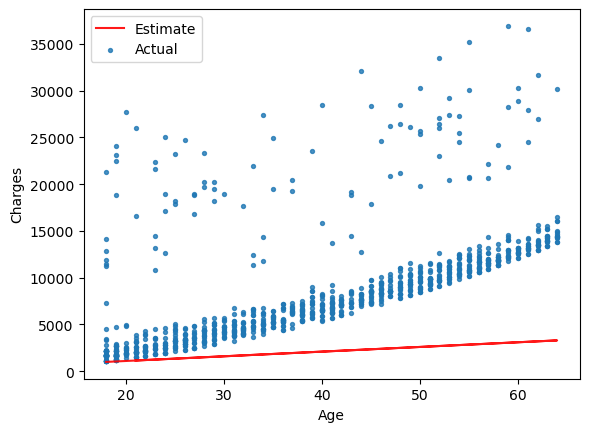

In [15]:
try_parameters(non_smoker_df, 50, 100)

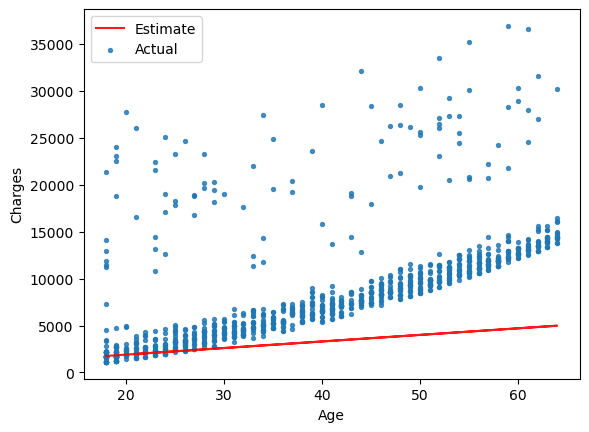

In [16]:
try_parameters(non_smoker_df, 70, 500)

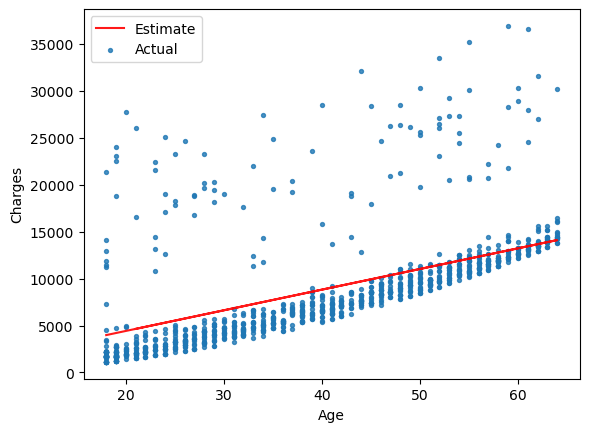

In [17]:
try_parameters(non_smoker_df, 220, 20)

**Завдання 6**: Напишіть фукнцію для обчислення root mean squared error згідно з формулою цієї метрики точності моделі з використанням `numpy`.

Обчисліть RMSE для тих пар пареметрів, які Ви спробували в завданні 5.

Яке найнижче значення втрат ви зможете досягти? Чи можете ви придумати загальну стратегію для знаходження кращих значень $w$ та $b$ методом проб та помилок?

In [18]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

In [19]:
# Фактичні значення
y_true = df['charges'].values

# Значення ознаки (наприклад, age)
x = df['age'].values

# Пари параметрів (theta0, theta1)
params = [
    (50, 100),
    (70, 500),
    (220, 20)
]

for theta0, theta1 in params:
    y_pred = theta0 + theta1 * x
    error = rmse(y_true, y_pred)

    print(f'theta0={theta0}, theta1={theta1}, RMSE={error:.2f}')

theta0=50, theta1=100, RMSE=14994.42
theta0=70, theta1=500, RMSE=13638.88
theta0=220, theta1=20, RMSE=17177.02


In [20]:
best_rmse = float('inf')
best_w = 0
best_b = 0

y_true = df['charges'].values
x = df['age'].values

for w in range(0, 1000, 5):
    for b in range(-15000, 15000, 5):
        y_pred = w * x + b
        error = rmse(y_true, y_pred)

        if error < best_rmse:
            best_rmse = error
            best_w = w
            best_b = b

print(f'Найкращий w: {best_w}')
print(f'Найкращий b: {best_b}')
print(f'Найменший RMSE: {best_rmse:.2f}')

Найкращий w: 260
Найкращий b: 3075
Найменший RMSE: 11551.71


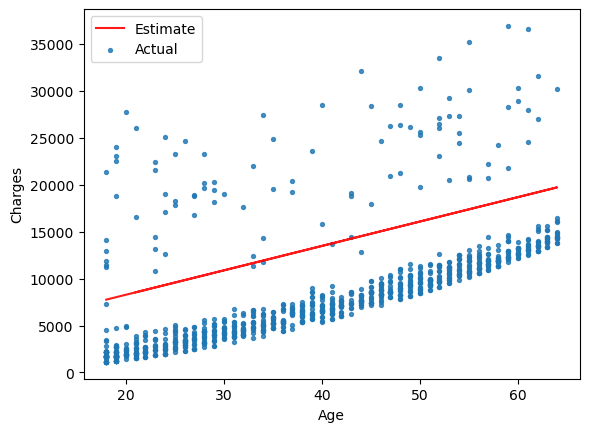

In [21]:
try_parameters(non_smoker_df, 260, 3075)